# Tạo data set

code mới

In [ ]:
import numpy as np
import pandas as pd

# 1. THIẾT LẬP THÔNG SỐ BAN ĐẦU VÀ TÍNH TÁI LẬP (REPRODUCIBILITY)
# Thiết lập seed để đảm bảo mỗi lần chạy đều ra cùng một kết quả dữ liệu
np.random.seed(42)

num_sprints = 50
cases_per_sprint = 100
total_samples = num_sprints * cases_per_sprint  # Đúng 5.000 mẫu theo chuyên đề

print(f"--- Bắt đầu quy trình sinh {total_samples} mẫu dữ liệu qua {num_sprints} Sprint ---")

# Tạo mảng danh sách các Sprint tăng dần theo thời gian (Tuân thủ chuỗi thời gian)
sprint_ids = np.repeat(np.arange(1, num_sprints + 1), cases_per_sprint)
# Tạo mã định danh kịch bản kiểm thử (Test Case ID) chạy trong mỗi Sprint
test_case_ids = np.tile(np.arange(1, cases_per_sprint + 1), num_sprints)


# 2. PHÂN PHỐI PARETO (ĐỊNH LUẬT 80/20) CHO ĐẶC TRƯNG "LỊCH SỬ LỖI"
# Giả định 20% số ca kiểm thử nằm trong module nhạy cảm (High-risk cluster) và chiếm 80% tỷ lệ lỗi
is_high_risk_cluster = np.random.binomial(1, 0.2, total_samples)

# Nếu thuộc cụm rủi ro cao, số lần fail trong quá khứ tuân theo phân phối Poisson biên độ lớn (Lam=6)
# Nếu thuộc cụm an toàn, số lần fail tuân theo phân phối Poisson biên độ nhỏ (Lam=0.5)
failure_history = np.where(
    is_high_risk_cluster == 1,
    np.random.poisson(lam=6, size=total_samples),
    np.random.poisson(lam=0.5, size=total_samples)
)


# 3. SINH CÁC ĐẶC TRƯNG TĨNH VÀ ĐỘNG THEO QUY LUẬT PHẦN MỀM (MỤC 3.2)
# Khối lượng mã thay đổi (Code Churn): Sinh bằng phân phối Poisson (Lam=45 dòng code)
code_churn = np.random.poisson(lam=45, size=total_samples)

# Độ phức tạp Cyclomatic: Mã nguồn thông thường có độ phức tạp trung bình là 6-8 nhánh rẽ
cyclomatic_complexity = np.random.poisson(lam=8, size=total_samples)

# Độ phụ thuộc (Dependencies): Số lượng module liên kết, sinh theo phân phối Poisson (Lam=3)
dependencies = np.random.poisson(lam=3, size=total_samples)

# Thời gian thực thi (ms): Sinh theo phân phối chuẩn (Normal Distribution) quanh mức 1500ms
execution_time = np.random.normal(loc=1500, scale=350, size=total_samples).astype(int)
execution_time = np.clip(execution_time, 100, None)  # Đảm bảo thời gian không bị âm

# Tuổi của ca kiểm thử (Test Age): Số chu kỳ chưa đổi, sinh ngẫu nhiên từ 1 đến 12 Sprint
test_age = np.random.randint(1, 13, size=total_samples)


# 4. CƠ CHẾ ÁNH XẠ BIẾN VÀ TÍNH ĐIỂM RỦI RO (HÀM LOGISTIC / SIGMOID)
# Định nghĩa các trọng số Beta thể hiện mối tương quan nhân - quả logic (Mục 3.1.2)
beta_churn = 0.015       # Code thay đổi càng nhiều -> Rủi ro càng tăng (Dương)
beta_complex = 0.12      # Độ phức tạp cao -> Rủi ro tăng mạnh (Dương)
beta_depend = 0.08       # Ít ảnh hưởng hơn nhưng vẫn làm tăng rủi ro (Dương)
beta_fail_hist = 0.45    # Lịch sử thường xuyên fail -> Khả năng cao lại tái diễn (Dương mạnh)
beta_age = -0.18         # Test case lâu đời không bắt được lỗi -> Thường dư thừa/an toàn (Âm)

# Tính giá trị Logit (z) dựa trên tổ hợp tuyến tính các đặc trưng
z_raw = (beta_churn * code_churn +
         beta_complex * cyclomatic_complexity +
         beta_depend * dependencies +
         beta_fail_hist * failure_history +
         beta_age * test_age)

# Tính xác suất lỗi P(Y=1) thông qua hàm kích hoạt Sigmoid
probabilities = 1 / (1 + np.exp(-z_raw))

# Để đảm bảo phân phối nhãn nền tảng đạt chính xác tỷ lệ 10/90 (Mục 3.1.1)
# Ta lấy ngưỡng quyết định (Threshold) tại phân vị thứ 90 (90th percentile) của xác suất
threshold_90 = np.percentile(probabilities, 90)
labels = np.where(probabilities >= threshold_90, 1, 0)


# 5. KỸ THUẬT TIÊM NHIỄU NGẪU NHIÊN GIẢ LẬP HÀNH VI CON NGƯỜI (NOISE INJECTION)
# Chủ động lấy ngẫu nhiên 3% số lượng mẫu để đảo nhãn (Flip Labels)
noise_rate = 0.03
num_noise_samples = int(total_samples * noise_rate)
noise_indices = np.random.choice(total_samples, size=num_noise_samples, replace=False)

# Tiến hành đảo nhãn: 1 thành 0, 0 thành 1 để phá vỡ ranh giới toán học cứng nhắc
labels[noise_indices] = 1 - labels[noise_indices]


# 6. ĐÓNG GÓI THÀNH DANH SÁCH CẤU TRÚC (DATAFRAME) VÀ KIỂM CHỨNG TRỰC QUAN
df_synthetic = pd.DataFrame({
    'Sprint_ID': sprint_ids,
    'TestCase_ID': test_case_ids,
    'Code_Churn': code_churn,
    'Cyclomatic_Complexity': cyclomatic_complexity,
    'Dependencies': dependencies,
    'Failure_History': failure_history,
    'Execution_Time_ms': execution_time,
    'Test_Age': test_age,
    'Label': labels
})

# Kiểm tra phân phối nhãn thực tế sau khi đã tiêm nhiễu
label_counts = df_synthetic['Label'].value_counts(normalize=True) * 100

print("\n--- Quy trình sinh dữ liệu hoàn tất thành công! ---")
print(f"Tổng số bản ghi thu được: {df_synthetic.shape[0]} dòng, {df_synthetic.shape[1]} cột.")
print(f"Tỷ lệ phân phối Nhãn thực tế trong Dataset:")
print(f"  + Nhãn 0 (Ca kiểm thử An toàn): {label_counts[0]:.2f}%")
print(f"  + Nhãn 1 (Ca kiểm thử Có lỗi): {label_counts[1]:.2f}%")

# Xuất thử 5 dòng đầu tiên để kiểm tra cấu trúc dữ liệu
print("\nXem trước 5 bản ghi đầu tiên của Hệ thống:")
print(df_synthetic.head())

# (Tùy chọn) Xuất dữ liệu ra file CSV để nạp vào bước huấn luyện mô hình ở mục sau
df_synthetic.to_csv('synthetic_regression_testing_data.csv', index=False)

--- Bắt đầu quy trình sinh 5000 mẫu dữ liệu qua 50 Sprint ---

--- Quy trình sinh dữ liệu hoàn tất thành công! ---
Tổng số bản ghi thu được: 5000 dòng, 9 cột.
Tỷ lệ phân phối Nhãn thực tế trong Dataset:
  + Nhãn 0 (Ca kiểm thử An toàn): 87.72%
  + Nhãn 1 (Ca kiểm thử Có lỗi): 12.28%

Xem trước 5 bản ghi đầu tiên của Hệ thống:
   Sprint_ID  TestCase_ID  Code_Churn  Cyclomatic_Complexity  Dependencies  \
0          1            1          45                      4             3   
1          1            2          61                     11             5   
2          1            3          50                      7             1   
3          1            4          46                      8             2   
4          1            5          39                     10             5   

   Failure_History  Execution_Time_ms  Test_Age  Label  
0                1               1425         4      0  
1                6               2207         1      1  
2                0              

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Code cũ

# Mô hình training


Code mới lần 2

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import precision_score, recall_score, f1_score

# Yêu cầu cài đặt imbalanced-learn nếu chạy ở môi trường cục bộ (Colab đã có sẵn)
# !pip install imbalanced-learn
from imblearn.over_sampling import SMOTE

# --- GIAI ĐOẠN 1: CHUẨN BỊ ĐẦU VÀO LUỒNG DỮ LIỆU ---
# Giả định dữ liệu 'df_synthetic' từ bước trước đã sẵn sàng trong bộ nhớ
# Sắp xếp nghiêm ngặt theo trình tự thời gian tăng dần của các Sprint
df_synthetic = df_synthetic.sort_values(by='Sprint_ID').reset_index(drop=True)

# Tách biệt tập đặc trưng biến độc lập (X) và nhãn mục tiêu (y)
# Loại bỏ các trường định danh không mang giá trị học máy để tránh gây nhiễu hệ thống
X = df_synthetic.drop(columns=['Sprint_ID', 'TestCase_ID', 'Label'])
y = df_synthetic['Label']

# --- GIAI ĐOẠN 2: THIẾT LẬP CƠ CHẾ KIỂM CHỨNG CHUỖI THỜI GIAN ---
# Thiết lập không gian chia cửa sổ cuốn chiếu (ví dụ: 5 vòng lặp tịnh tiến thời gian)
n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits)

# Khởi tạo cấu trúc lưu trữ kết quả đánh giá cho từng mô hình qua các vòng lặp
results = {
    'Random Forest': {'precision': [], 'recall': [], 'f1': []},
    'SVM': {'precision': [], 'recall': [], 'f1': []},
    'Gradient Boosting': {'precision': [], 'recall': [], 'f1': []}
}

print(f"--- Bắt đầu quy trình huấn luyện cuốn chiếu với {n_splits} vòng lặp tịnh tiến ---")

# --- GIAI ĐOẠN 3: VÒNG LẶP HUẤN LUYỆN VÀ ĐÁNH GIÁ CUỐN CHIẾU (ROLLING WINDOW) ---
for fold, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"\n[Vòng lặp {fold + 1}/{n_splits}]")

    # Phân chia dữ liệu theo chỉ số thời gian (Chặn đứng hoàn toàn hiện tượng Data Leakage)
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Xác định phạm vi Sprint đang thực hiện kiểm thử trong vòng lặp này
    start_sprint_test = df_synthetic.iloc[test_index]['Sprint_ID'].min()
    end_sprint_test = df_synthetic.iloc[test_index]['Sprint_ID'].max()
    print(f"  + Huấn luyện trên các mẫu quá khứ từ mốc xuất phát đến trước Sprint {start_sprint_test}")
    print(f"  + Dự đoán 'mù' trên không gian tương lai: Từ Sprint {start_sprint_test} đến Sprint {end_sprint_test}")

    # 1. Chuẩn hóa thang đo đặc trưng số học (Feature Scaling)
    scaler = StandardScaler()
    # Chỉ học tham số scale (fit) trên tập Train quá khứ, sau đó ép thang đo lên cả hai tập
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # 2. Xử lý mất cân bằng dữ liệu bằng kỹ thuật SMOTE
    # TUYỆT ĐỐI chỉ áp dụng trên tập Train để thuật toán không học vẹt. Tập Test giữ nguyên bản chất 10/90.
    smote = SMOTE(random_state=42)
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

    # 3. Cấu hình và Khởi tạo 3 Thuật toán phân lớp cốt lõi
    models = {
        'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
        'SVM': SVC(kernel='rbf', class_weight='balanced', random_state=42),
        'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
    }

    # 4. Thực thi quy trình Học và Trích xuất chỉ số hiệu năng
    for model_name, model in models.items():
        # Gọi hàm fit() để mô hình học các quy luật nhân quả
        model.fit(X_train_resampled, y_train_resampled)

        # Mô hình tiến hành suy diễn dự đoán trên tập kiểm thử (Testing set) độc lập
        y_pred = model.predict(X_test_scaled)

        # Tính toán các độ đo hiệu năng của vòng lặp hiện tại
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)

        # Lưu trữ kết quả của thuật toán
        results[model_name]['precision'].append(prec)
        results[model_name]['recall'].append(rec)
        results[model_name]['f1'].append(f1)

        # =====================================================================
        # BƯỚC MÔ PHỎNG TRIỂN KHAI THỰC TẾ: LỌC TẬP T' VÀ LẤY LẠI TESTCASE_ID
        # =====================================================================

        # 1. Lấy lại bản sao của dữ liệu GỐC (chứa ID) tương ứng với tập Test hiện tại
        df_test_original = df_synthetic.iloc[test_index]

        # 2. Dùng mảng y_pred làm mặt nạ (mask) để lọc ra các dòng mà AI đoán là 1
        T_prime_df = df_test_original[y_pred == 1]

        # 3. Trích xuất đúng cột TestCase_ID thành một danh sách (list)
        danh_sach_chay_thuc_te = T_prime_df['TestCase_ID'].tolist()

        # Chỉ in kết quả trích xuất ID ở Vòng lặp cuối cùng (để màn hình đỡ rối)
        if fold == n_splits - 1:
            print(f"    [Triển khai CI/CD] {model_name} đề xuất tập T' gồm {len(danh_sach_chay_thuc_te)}/{len(y_test)} Test Case.")
            print(f"    -> Danh sách ID đẩy lên máy chủ: {danh_sach_chay_thuc_te[:15]}... (hiển thị 15 ID đầu)")

        # THÊM DÒNG NÀY VÀO ĐỂ XUẤT FILE CÓ ĐẦY ĐỦ TESTCASE_ID NHÉ BẠN:
            T_prime_df.to_csv(f'T_prime_{model_name}.csv', index=False)

        # =====================================================================


# --- GIAI ĐOẠN 4: TỔNG HỢP VÀ KẾT XUẤT BẢNG HIỆU NĂNG TRUNG BÌNH (CHƯƠNG 4) ---
print("\n" + "="*50)
print("BẢNG TỔNG HỢP HIỆU NĂNG MÔ HÌNH SAU KHI CHẠY TIME-SERIES SPLIT")
print("="*50)

summary_data = []
for model_name in results.keys():
    # Tính giá trị trung bình (Mean) của các độ đo qua các vòng lặp cuốn chiếu
    avg_precision = np.mean(results[model_name]['precision']) * 100
    avg_recall = np.mean(results[model_name]['recall']) * 100
    avg_f1 = np.mean(results[model_name]['f1']) * 100

    summary_data.append({
        'Thuật toán / Mô hình': model_name,
        'Độ chính xác (Precision)': f"{avg_precision:.2f}%",
        'Độ thu hồi (Recall)': f"{avg_recall:.2f}%",
        'Điểm F1-Score': f"{avg_f1:.2f}%"
    })

# Chuyển đổi cấu trúc sang dạng bảng biểu hiển thị trực quan
df_summary = pd.DataFrame(summary_data)
print(df_summary.to_string(index=False))
print("="*50)

--- Bắt đầu quy trình huấn luyện cuốn chiếu với 5 vòng lặp tịnh tiến ---

[Vòng lặp 1/5]
  + Huấn luyện trên các mẫu quá khứ từ mốc xuất phát đến trước Sprint 9
  + Dự đoán 'mù' trên không gian tương lai: Từ Sprint 9 đến Sprint 17

[Vòng lặp 2/5]
  + Huấn luyện trên các mẫu quá khứ từ mốc xuất phát đến trước Sprint 17
  + Dự đoán 'mù' trên không gian tương lai: Từ Sprint 17 đến Sprint 26

[Vòng lặp 3/5]
  + Huấn luyện trên các mẫu quá khứ từ mốc xuất phát đến trước Sprint 26
  + Dự đoán 'mù' trên không gian tương lai: Từ Sprint 26 đến Sprint 34

[Vòng lặp 4/5]
  + Huấn luyện trên các mẫu quá khứ từ mốc xuất phát đến trước Sprint 34
  + Dự đoán 'mù' trên không gian tương lai: Từ Sprint 34 đến Sprint 42

[Vòng lặp 5/5]
  + Huấn luyện trên các mẫu quá khứ từ mốc xuất phát đến trước Sprint 42
  + Dự đoán 'mù' trên không gian tương lai: Từ Sprint 42 đến Sprint 50
    [Triển khai CI/CD] Random Forest đề xuất tập T' gồm 81/833 Test Case.
    -> Danh sách ID đẩy lên máy chủ: [58, 72, 76, 92, 9

Biểu đồ sự bùng nổ ca kiểm thử

✅ Đã vẽ và lưu biểu đồ thành công vào file: Hinh_1_1_Su_bung_no_Test_Case.png


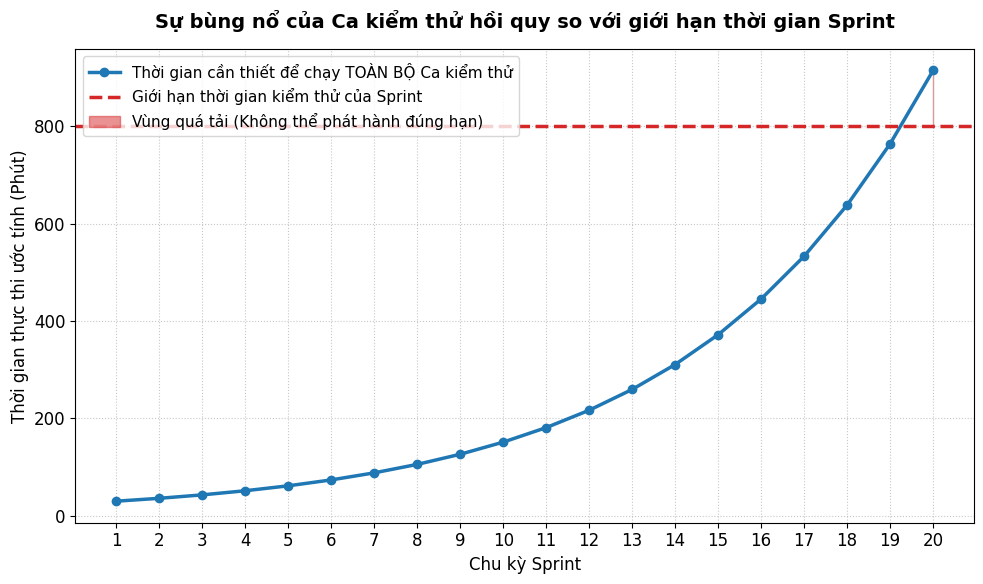

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Cài đặt phông chữ và kích thước chuẩn học thuật
plt.rcParams.update({'font.size': 12, 'font.family': 'sans-serif'})

# Tạo dữ liệu giả lập cho 20 Sprints
sprints = np.arange(1, 21)

# Số lượng Test Case tăng dần (mô phỏng tăng theo hàm mũ nhẹ do dự án phình to)
test_cases = 50 * np.exp(0.18 * sprints)

# Giả sử mỗi Test Case chạy mất 0.5 phút -> Tổng thời gian cần để chạy
time_required = test_cases * 0.5

# Giới hạn thời gian tối đa cho phép chạy Test trong 1 Sprint (Ví dụ: 800 phút)
sprint_time_limit = np.full(20, 800)

# Khởi tạo biểu đồ
plt.figure(figsize=(10, 6))

# Vẽ đường Thời gian yêu cầu thực tế (đường cong đi lên)
plt.plot(sprints, time_required, marker='o', linewidth=2.5, color='#1f77b4',
         label='Thời gian cần thiết để chạy TOÀN BỘ Ca kiểm thử')

# Vẽ đường Giới hạn thời gian Sprint (đường ngang đứt nét)
plt.axhline(y=800, color='#d62728', linestyle='--', linewidth=2.5,
            label='Giới hạn thời gian kiểm thử của Sprint')

# Đánh dấu vùng "Nút thắt cổ chai" (Vùng quá tải)
plt.fill_between(sprints, time_required, 800, where=(time_required > 800),
                 color='#d62728', alpha=0.5, label='Vùng quá tải (Không thể phát hành đúng hạn)')

# Cấu hình các nhãn trục và tiêu đề
plt.title('Sự bùng nổ của Ca kiểm thử hồi quy so với giới hạn thời gian Sprint', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Chu kỳ Sprint', fontsize=12)
plt.ylabel('Thời gian thực thi ước tính (Phút)', fontsize=12)

# Cấu hình mốc trục X (chỉ hiện số nguyên)
plt.xticks(np.arange(1, 21, step=1))

# Thêm chú thích (Legend)
plt.legend(loc='upper left', fontsize=11)

# Thêm lưới cho dễ nhìn
plt.grid(True, linestyle=':', alpha=0.7)

# Lưu hình ảnh ra file PNG với độ phân giải cao (300 dpi để in luận văn không bị mờ)
file_name = "Hinh_1_1_Su_bung_no_Test_Case.png"
plt.tight_layout()
plt.savefig(file_name, dpi=300)

print(f"✅ Đã vẽ và lưu biểu đồ thành công vào file: {file_name}")